# Roi Analysis

Owner: 

Input: 

Output: 

ROI Analysis
Objective
The objective of this analysis is to evaluate the effectiveness of marketing investments using Return on Investment (ROI) and Return on Advertising Spend (ROAS). This analysis identifies the effectiveness of marketing expenditures and provides insights for future marketing decisions.

In [1]:
import sys
sys.path.append('..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('default')
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv(
    "../data/processed/feature_engineered_marketing_mix_data.csv"
)

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (36, 44)


,month,country,brand_category,region_scope,tv_spend_lkr,facebook_instagram_spend_lkr,google_search_spend_lkr,youtube_spend_lkr,radio_spend_lkr,outdoor_spend_lkr,...,revenue_per_unit,revenue_per_conversion,roas,cost_per_conversion,lag_1_total_spend,lag_2_total_spend,rolling_3_month_spend,marketing_pressure,competitive_advantage,promotion_impact
0,2023-01-01,Sri Lanka,FMCG - Packaged Foods,National,4274762,3890003,2467793,1836858,1700676,1813444,...,558.637776,57.943069,4.386643,13.208977,0.0,0.0,0.000000e+00,12469416,50.4,7.8516
1,2023-02-01,Sri Lanka,FMCG - Packaged Foods,National,4023574,5062635,2962576,2254198,1922384,2941194,...,633.780115,110.710778,3.839737,28.832909,15983536.0,0.0,0.000000e+00,14302983,49.0,9.0912
2,2023-03-01,Sri Lanka,FMCG - Packaged Foods,National,5359091,3746337,4080535,2363737,1720670,2063917,...,562.908050,223.483184,4.399608,50.796156,19166561.0,15983536.0,1.816146e+07,15549700,54.1,6.8300
3,2023-04-01,Sri Lanka,FMCG - Packaged Foods,National,5102550,3690115,3390558,2595121,1217450,3091430,...,533.883913,81.452943,5.242138,15.538116,19334287.0,19166561.0,1.919602e+07,14778344,68.8,25.6088
4,2023-05-01,Sri Lanka,FMCG - Packaged Foods,National,4972723,5333813,3240078,2343364,1568285,3525300,...,461.062423,137.662905,3.693476,37.271909,19087224.0,19334287.0,1.980169e+07,15889978,47.0,2.1450


Overall ROI Calculation
Return on Investment (ROI) measures the profitability of marketing investments.

Formula:

ROI = ((Revenue - Cost) / Cost) × 100

In [3]:
channel_cols = [
    'tv_spend_lkr',
    'facebook_instagram_spend_lkr',
    'google_search_spend_lkr',
    'youtube_spend_lkr',
    'radio_spend_lkr',
    'outdoor_spend_lkr'
]

total_revenue = df['sales_revenue_lkr'].sum()

total_spend = df[channel_cols].sum().sum()

overall_roi = (
    (total_revenue - total_spend)
    / total_spend
) * 100

print(f"Total Revenue : LKR {total_revenue:,.2f}")
print(f"Total Spend   : LKR {total_spend:,.2f}")
print(f"Overall ROI   : {overall_roi:.2f}%")

Total Revenue : LKR 3,064,268,780.86
Total Spend   : LKR 668,740,524.00
Overall ROI   : 358.21%


The overall marketing ROI was 358.21%, indicating that advertising investments generated significantly higher revenue than their associated costs. This demonstrates the effectiveness of the company's marketing strategy during the analysis period.

ROAS Analysis
Return on Advertising Spend (ROAS) measures the amount of revenue generated for each unit of advertising expenditure.

ROAS = Revenue / Advertising Spend

In [4]:
df["roas"].describe()

count    36.000000
mean      4.661235
std       0.655167
min       3.693476
25%       4.218642
50%       4.499897
75%       5.170118
max       6.138614
Name: roas, dtype: float64

The average ROAS was 4.66, indicating that every LKR 1 spent on advertising generated approximately LKR 4.66 in revenue. The maximum ROAS observed was 6.14, while the minimum ROAS was 3.69, demonstrating variations in campaign effectiveness across different periods.

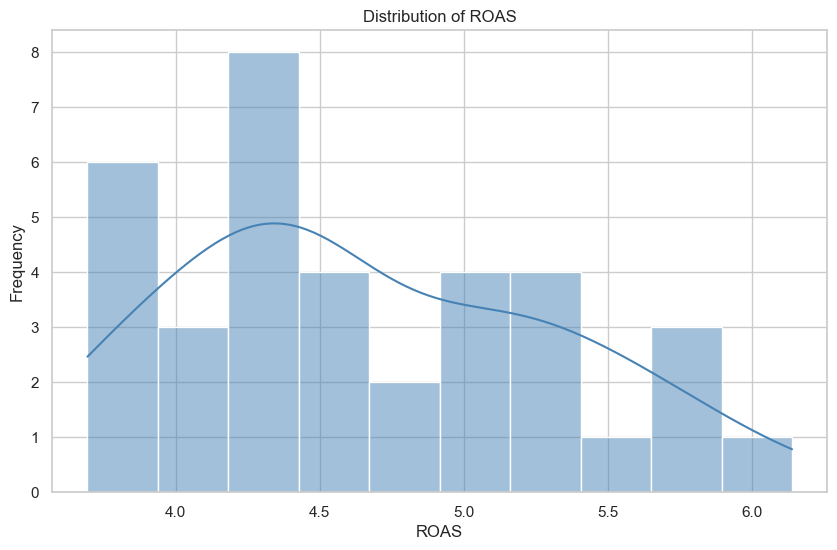

In [5]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["roas"],
    bins=10,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of ROAS")
plt.xlabel("ROAS")
plt.ylabel("Frequency")

plt.show()

Channel Spending Analysis
This section examines how advertising budgets were distributed across different marketing channels.

In [6]:
channel_cols = [
    'tv_spend_lkr',
    'facebook_instagram_spend_lkr',
    'google_search_spend_lkr',
    'youtube_spend_lkr',
    'radio_spend_lkr',
    'outdoor_spend_lkr'
]

channel_spend = df[channel_cols].sum()

channel_spend.sort_values(
    ascending=False
)

facebook_instagram_spend_lkr    158343617
tv_spend_lkr                    156964242
google_search_spend_lkr         119353135
outdoor_spend_lkr                94057802
youtube_spend_lkr                79913729
radio_spend_lkr                  60107999
dtype: int64

Facebook and Instagram received the highest advertising investment, followed closely by TV advertising. Radio received the lowest budget allocation among all channels. This indicates a stronger focus on digital advertising and mass media channels.

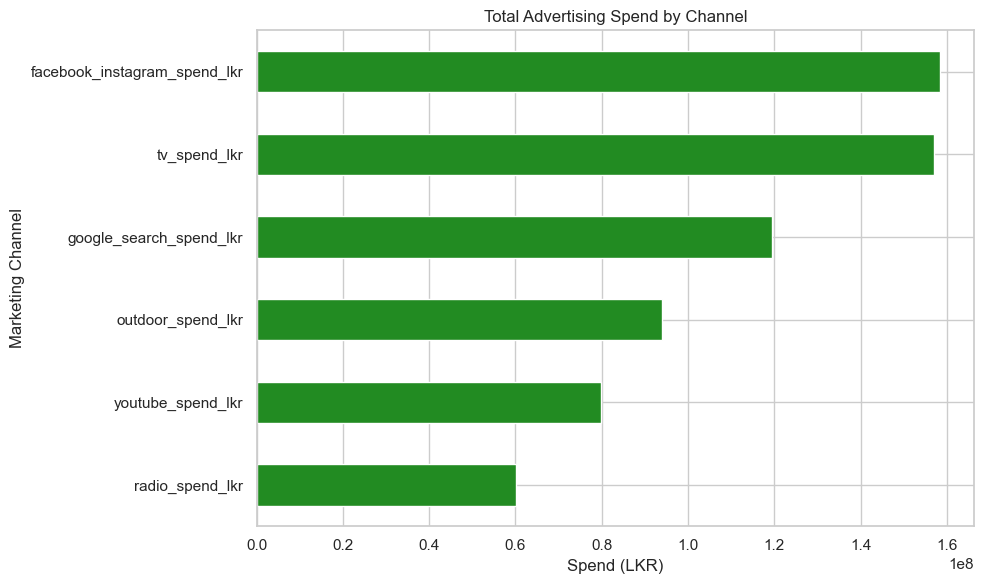

In [7]:
plt.figure(figsize=(10,6))

channel_spend.sort_values().plot(
    kind='barh',
    color='forestgreen'
)

plt.title("Total Advertising Spend by Channel")
plt.xlabel("Spend (LKR)")
plt.ylabel("Marketing Channel")

plt.tight_layout()
plt.show()

Spending Distribution Analysis
Facebook and Instagram received the highest advertising budget allocation, followed closely by TV advertising. Google Search also received a significant portion of the marketing budget. Radio advertising received the lowest investment among all marketing channels.

The results indicate that the company focused primarily on digital and mass-media advertising channels.

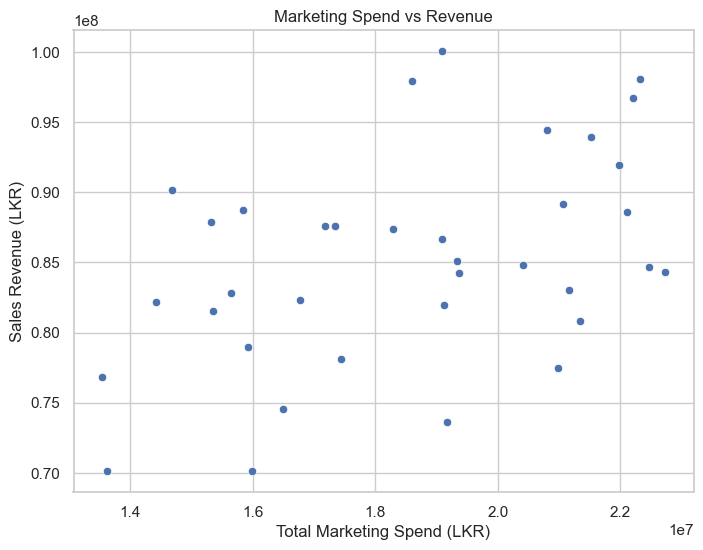

In [8]:
df["total_spend"] = (
    df[
        [
            'tv_spend_lkr',
            'facebook_instagram_spend_lkr',
            'google_search_spend_lkr',
            'youtube_spend_lkr',
            'radio_spend_lkr',
            'outdoor_spend_lkr'
        ]
    ].sum(axis=1)
)

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="total_spend",
    y="sales_revenue_lkr"
)

plt.title("Marketing Spend vs Revenue")
plt.xlabel("Total Marketing Spend (LKR)")
plt.ylabel("Sales Revenue (LKR)")

plt.show()


Spend vs Revenue Insights
The correlation coefficient between total marketing spend and sales revenue is 0.45, indicating a moderate positive relationship. This suggests that increases in advertising expenditure generally contribute to higher sales revenue, although other factors also influence business performance.

In [9]:
df[
    ["total_spend", "sales_revenue_lkr"]
].corr()

,total_spend,sales_revenue_lkr
total_spend,1.000000,0.451727
sales_revenue_lkr,0.451727,1.000000


In [10]:
best_month = df.loc[df["roas"].idxmax()]

worst_month = df.loc[df["roas"].idxmin()]

print("Best Performing Month")
print(best_month[["month", "roas"]])

print("\nWorst Performing Month")
print(worst_month[["month", "roas"]])

Best Performing Month
month    2024-04-01
roas       6.138614
Name: 15, dtype: object

Worst Performing Month
month    2023-05-01
roas       3.693476
Name: 4, dtype: object


Performance Insights
The highest advertising efficiency was recorded in April 2024 with a ROAS of 6.14, meaning that every LKR 1 spent on advertising generated approximately LKR 6.14 in revenue.

The lowest advertising efficiency was observed in May 2023 with a ROAS of 3.69. Although revenue was still generated, advertising effectiveness was comparatively lower during this period.

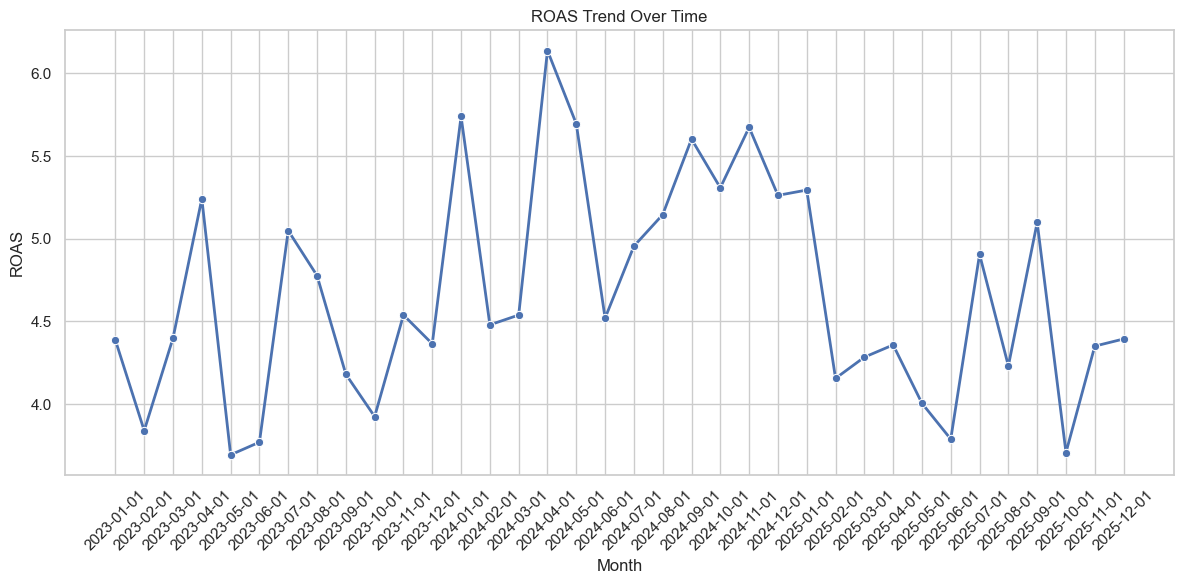

In [11]:
plt.figure(figsize=(12,6))

sns.lineplot(
    data=df,
    x='month',
    y='roas',
    marker='o',
    linewidth=2
)

plt.title("ROAS Trend Over Time")
plt.xlabel("Month")
plt.ylabel("ROAS")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Key Findings
The overall marketing ROI was 358.21%, indicating strong returns from advertising investments.
The average ROAS was 4.66, meaning that every LKR 1 spent on advertising generated approximately LKR 4.66 in revenue.

Facebook and Instagram received the highest advertising expenditure, followed by TV advertising.

Marketing spend and sales revenue showed a moderate positive correlation (0.45), suggesting that increased advertising investments generally contribute to higher revenue.

The highest advertising efficiency was observed in April 2024 with a ROAS of 6.14, while the lowest efficiency was recorded in May 2023 with a ROAS of 3.69.

The results indicate that marketing investments generated substantial business value throughout the analysis period.

Recommendations
Continue investing in high-performing advertising channels that contribute significantly to revenue generation.
Maintain strong investment in Facebook/Instagram and TV advertising, as these channels received considerable budget allocation and support overall marketing performance.

Further evaluate Google Search campaigns since Marketing Mix Modeling identified Google Search as one of the most influential channels.

Monitor ROAS regularly and investigate periods with lower advertising efficiency to identify possible optimization opportunities.

Apply budget optimization techniques to allocate future advertising budgets more effectively and maximize ROI.

Conclusion
The ROI analysis demonstrates that marketing investments generated strong financial returns during the analysis period. An overall ROI of 358.21% and an average ROAS of 4.66 indicate that advertising expenditure contributed significantly to revenue generation. The findings reveal a positive relationship between marketing spend and sales performance and provide valuable insights for future budget allocation and marketing strategy decisions.